# 5A. Transfer Learning - Caltech-101 (VGG16)

In [1]:
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
train = keras.utils.image_dataset_from_directory(
    "../datasets/Object Detection/caltech-101",
    image_size=(128, 128), validation_split=0.2, subset="training", seed=42)
val = keras.utils.image_dataset_from_directory(
    "../datasets/Object Detection/caltech-101",
    image_size=(128, 128), validation_split=0.2, subset="validation", seed=42)

class_names = train.class_names
n_classes = len(class_names)
print("classes:", n_classes)

train = train.prefetch(2)
val = val.prefetch(2)

Found 9144 files belonging to 102 classes.


Using 7316 files for training.


Found 9144 files belonging to 102 classes.


Using 1828 files for validation.


classes: 102


In [3]:
base = keras.applications.VGG16(include_top=False, input_shape=(128, 128, 3))
base.trainable = False

model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(n_classes, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 102)            │        13,158 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,793,510 (56.43 MB)

 Trainable params: 78,822 (307.90 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [4]:
history = model.fit(train, validation_data=val, epochs=3)

Epoch 1/3
229/229 ━━━━━━━━━━━━━━━━━━━━ 326s 1s/step - accuracy: 0.3468 - loss: 3.1114 - val_accuracy: 0.5197 - val_loss: 2.2194
Epoch 2/3
229/229 ━━━━━━━━━━━━━━━━━━━━ 321s 1s/step - accuracy: 0.5894 - loss: 1.8120 - val_accuracy: 0.6324 - val_loss: 1.5643
Epoch 3/3
229/229 ━━━━━━━━━━━━━━━━━━━━ 305s 1s/step - accuracy: 0.6832 - loss: 1.3336 - val_accuracy: 0.6761 - val_loss: 1.3125


In [5]:
loss, acc = model.evaluate(val)
print(f"val acc (frozen base): {acc:.4f}")

 1/58 ━━━━━━━━━━━━━━━━━━━━ 1:00 1s/step - accuracy: 0.6562 - loss: 1.3178

 2/58 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.6719 - loss: 1.3248 

 3/58 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.6667 - loss: 1.3711

 4/58 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.6406 - loss: 1.4761

 5/58 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.6313 - loss: 1.5031

 6/58 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.6250 - loss: 1.4871

... (50 outputs left out)

57/58 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.6754 - loss: 1.3144

58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6761 - loss: 1.3125

58/58 ━━━━━━━━━━━━━━━━━━━━ 62s 1s/step - accuracy: 0.6761 - loss: 1.3125


val acc (frozen base): 0.6761


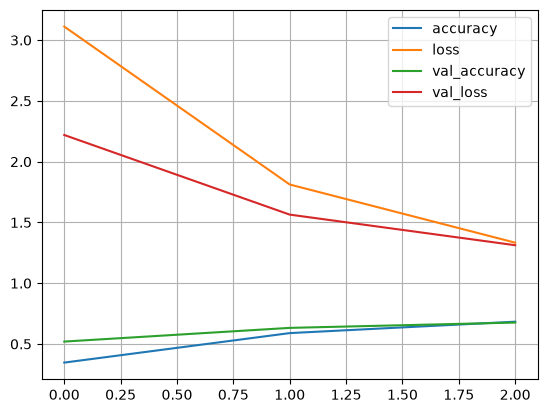

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()

## h. Visualize predictions

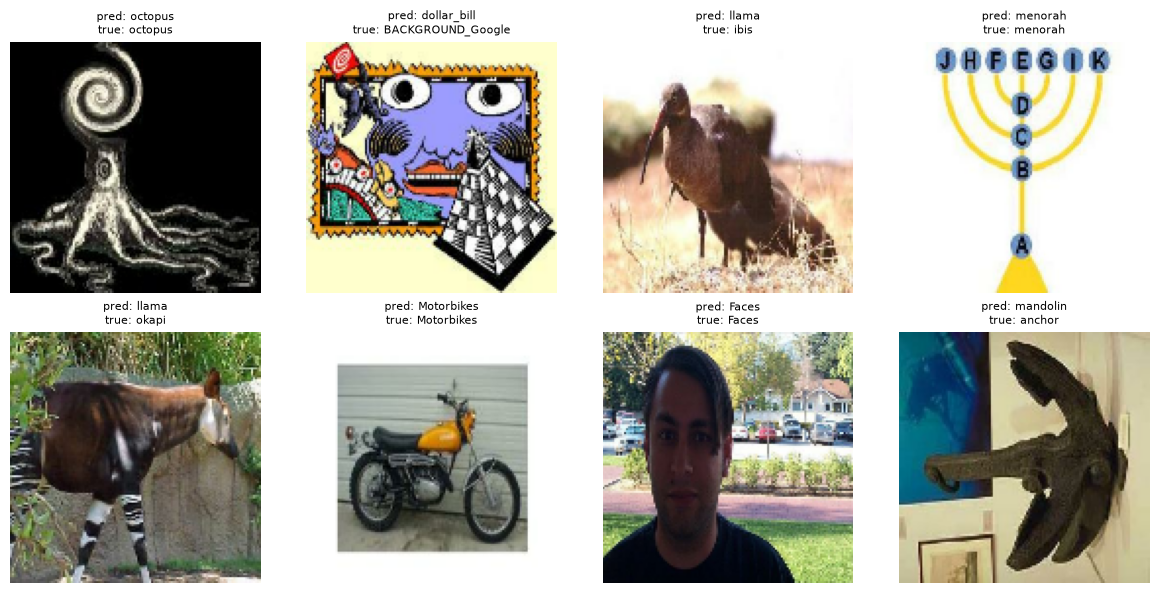

In [7]:
for images, labels in val.take(1):
    preds = model.predict(images)
    pred_classes = preds.argmax(axis=1)

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(f"pred: {class_names[pred_classes[i]]}\ntrue: {class_names[labels[i].numpy()]}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

## i. Fine-tune
Unfreeze the top layers of the pretrained base, recompile with a much smaller learning rate (1e-5), retrain for 2 epochs.

In [8]:
base.trainable = True
for layer in base.layers[:-4]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_ft = model.fit(train, validation_data=val, epochs=2)

Epoch 1/2


  1/229 ━━━━━━━━━━━━━━━━━━━━ 6:59 2s/step - accuracy: 0.6875 - loss: 1.4531

  2/229 ━━━━━━━━━━━━━━━━━━━━ 4:38 1s/step - accuracy: 0.7031 - loss: 1.2913

  3/229 ━━━━━━━━━━━━━━━━━━━━ 4:36 1s/step - accuracy: 0.7500 - loss: 1.1489

  4/229 ━━━━━━━━━━━━━━━━━━━━ 4:37 1s/step - accuracy: 0.7578 - loss: 1.1367

  5/229 ━━━━━━━━━━━━━━━━━━━━ 4:40 1s/step - accuracy: 0.7688 - loss: 1.0802

... (452 outputs left out)

227/229 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 0.8287 - loss: 0.6328

228/229 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.8288 - loss: 0.6328

229/229 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8286 - loss: 0.6329

229/229 ━━━━━━━━━━━━━━━━━━━━ 361s 2s/step - accuracy: 0.8286 - loss: 0.6329 - val_accuracy: 0.7850 - val_loss: 0.8138


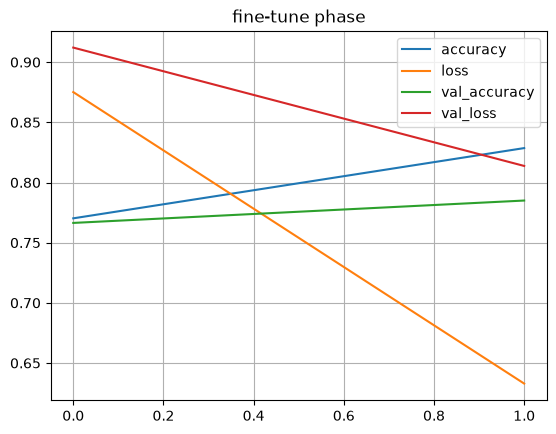

In [9]:
for k, v in history_ft.history.items():
    plt.plot(v, label=k)
plt.title("fine-tune phase")
plt.legend()
plt.grid()
plt.show()